# Solutions to the exercises of Chapter 4

Sample solutions for [Chapter 4, From the principle to field equations](../../notebooks/part1_principle/04_field_equations.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## Exercise 1. Excluded volume

With $f = k_BT\,[c\ln c - c - c\ln(1 - bc)]$,

$$ \frac{df}{dc} = k_BT\Big[\ln c - \ln(1 - bc) + \frac{bc}{1 - bc}\Big] , \qquad
   \Pi = c\,\frac{df}{dc} - f = \frac{k_BT\,c}{1 - bc} , \qquad
   D = \frac{1}{\zeta}\frac{\partial\Pi}{\partial c} = \frac{k_BT/\zeta}{(1 - bc)^2} . $$

The osmotic pressure is that of an ideal gas in the free length $1 - bc$ per unit
length, and the diffusion coefficient diverges as the rods approach close packing,
$bc \to 1$: a crowded region pushes itself apart strongly. The non-ideal part of
the chemical potential is $\mu_{\rm ex} = k_BT\,[-\ln(1 - bc) + bc/(1 - bc)]$.

In [2]:
c, b = sp.symbols("c b", positive=True)
f = c * sp.log(c) - c - c * sp.log(1 - b * c)
print("Pi / kT =", sp.simplify(c * sp.diff(f, c) - f), "    D zeta / kT =", sp.factor(sp.simplify(c * sp.diff(f, c, 2))))

edges = np.linspace(-10, 10, 2001)
xc, dx = 0.5 * (edges[1:] + edges[:-1]), edges[1] - edges[0]
pulse = np.exp(-xc**2 / (2 * 0.02)) / np.sqrt(2 * np.pi * 0.02)
print("\n   b     b c_max(0)    width at t = 1    width at t = 3")
for bb in (0.0, 0.2, 0.3):
    mu_ex = (lambda cc: -np.log(1 - bb * cc) + bb * cc / (1 - bb * cc)) if bb else None
    _, cs = on.smoluchowski_fv(pulse, edges, np.array([0.0, 1.0, 3.0]), mu_excess=mu_ex)
    widths = np.sqrt(np.sum(xc**2 * cs, axis=1) * dx)
    print(f"  {bb:.1f}      {bb * pulse.max():.2f}           {widths[1]:.3f}             {widths[2]:.3f}")
print(f"ideal, exact:                 {math.sqrt(0.02 + 2):.3f}             {math.sqrt(0.02 + 6):.3f}")

Pi / kT = -c/(b*c - 1)     D zeta / kT = (b*c - 1)**(-2)

   b     b c_max(0)    width at t = 1    width at t = 3
  0.0      0.00           1.421             2.453


  0.2      0.56           1.473             2.507


  0.3      0.85           1.500             2.535
ideal, exact:                 1.421             2.454


The rods spread faster than ideal particles. Most of the difference is made at
early times, when the pulse is dense; once it has spread, $bc \ll 1$ everywhere and
the two diffuse at the same rate, with the rods keeping their head start.

## Exercise 2. Sedimentation equilibrium

With $U = mgz$ and a dilute suspension, $\mu = k_BT\ln c + mgz$. Equation (4.3) stops
when $\mu$ is uniform:

$$ c(z) \propto e^{-z/\ell_g} , \qquad \ell_g = \frac{k_BT}{mg} . $$

This is the barometric distribution; $\ell_g$ is the height at which the
gravitational energy of a particle equals $k_BT$.

For the time, Eq. (4.2) gives each particle the velocity
$v = -(mg + k_BT\,\partial_z\ln c)/\zeta$. Where the suspension is uniform this is the
settling speed $mg/\zeta$, and a column of height $H$ clears in a time $H\zeta/mg$.
Diffusion matters only in the layer of thickness $\ell_g$ at the bottom.

In the cell $k_BT = \zeta = mg = 1$, so that $\ell_g = 1$, and $H = 20$.

time          :     0      5     10     15     20     25     30     60
mean height   : 10.00   6.03   3.40   1.94   1.32   1.10   1.03   1.00
largest difference from the barometric profile at t = 60: 1.5e-03   (c at the bottom: 19.8)


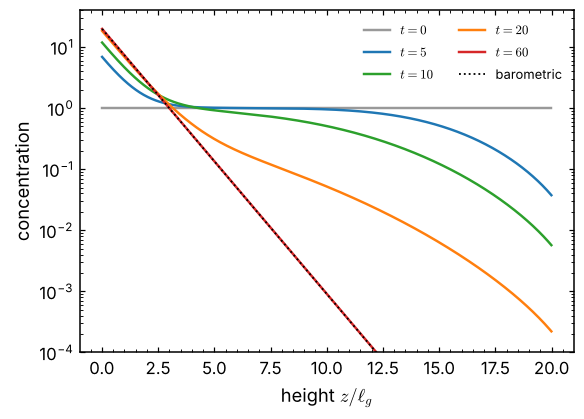

In [3]:
H = 20.0
edges = np.linspace(0, H, 801)
zc, dz = 0.5 * (edges[1:] + edges[:-1]), edges[1] - edges[0]
times = np.array([0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 60.0])
_, cs = on.smoluchowski_fv(np.ones_like(zc), edges, times, U=lambda z: z)
mean_height = (zc * cs).sum(axis=1) / cs.sum(axis=1)
c_eq = H * np.exp(-zc) / (1 - np.exp(-H))
print("time          :", "  ".join(f"{t:5.0f}" for t in times))
print("mean height   :", "  ".join(f"{m:5.2f}" for m in mean_height))
print(f"largest difference from the barometric profile at t = 60: {on.sup_error(cs[-1], c_eq):.1e}"
      f"   (c at the bottom: {c_eq[0]:.1f})")

fig, ax = plt.subplots(figsize=(5.2, 3.7))
for i, col in zip((0, 1, 2, 4, 7), ("0.6", "C0", "C2", "C1", "C3")):
    ax.semilogy(zc, np.maximum(cs[i], 1e-6), color=col, label=f"$t = {times[i]:g}$")
ax.semilogy(zc, c_eq, "k:", lw=1.2, label="barometric")
ax.set_ylim(1e-4, 40); ax.set_xlabel(r"height $z/\ell_g$"); ax.set_ylabel("concentration")
ax.legend(fontsize=8.5, ncol=2)
plt.show()

The clear front at the top of the column descends at the settling speed (unit
speed here) and reaches the sediment at $t \approx H\zeta/mg = 20$. While it does,
the mean height of the particles falls roughly as $(H - t)^2/2H$ (plus the
thickness of the sediment), and afterwards the profile settles onto the barometric
distribution. The small remaining difference is the discretisation of
the steep profile at the bottom.

## Exercise 3. Flow rate with porous drag

Integrating the profile of Section 4.6 across the channel,

$$ Q = \int_{-1}^{1}\frac{G}{\xi}\Big[1 - \frac{\cosh\alpha y}{\cosh\alpha}\Big]dy
     = \frac{2G}{\xi}\Big(1 - \frac{\tanh\alpha}{\alpha}\Big) . $$

For $\alpha \to 0$, $\tanh\alpha/\alpha = 1 - \alpha^2/3 + \dots$, and with
$\xi = \alpha^2\eta$ this gives $Q \to 2G/3\eta$, the Poiseuille result for a channel
of half-width 1. For $\alpha \to \infty$, $Q \to 2G/\xi$: the Darcy velocity $G/\xi$
times the width.

In [4]:
y, alpha, G, eta = sp.symbols("y alpha G eta", positive=True)
xi = alpha**2 * eta
Q = sp.simplify(sp.integrate(G / xi * (1 - sp.cosh(alpha * y) / sp.cosh(alpha)), (y, -1, 1)))
print("Q =", Q)
print("alpha -> 0:  ", sp.series(Q, alpha, 0, 3).removeO(), "       alpha -> infinity:  Q xi / G ->", sp.limit(Q * xi / G, alpha, sp.oo))

Q = 2*G*(alpha - tanh(alpha))/(alpha**3*eta)
alpha -> 0:   -4*G*alpha**2/(15*eta) + 2*G/(3*eta)        alpha -> infinity:  Q xi / G -> 2


## Exercise 4. Two dimensions

With $\Phi = \tfrac12\int c\,(\zeta_x v_x^2 + \zeta_y v_y^2)\,dS$ and
$\dot A = \int c\,\mathbf v\cdot\nabla\mu\,dS$ (the same integration by parts, now with
$\partial c/\partial t = -\nabla\cdot(c\mathbf v)$), the Rayleighian is minimised
point by point for each component:

$$ \zeta_x v_x = -\frac{\partial\mu}{\partial x} , \qquad \zeta_y v_y = -\frac{\partial\mu}{\partial y} . $$

For a dilute solution, $\mu = k_BT\ln c$, and conservation gives

$$ \frac{\partial c}{\partial t} = D_x\frac{\partial^2c}{\partial x^2} + D_y\frac{\partial^2c}{\partial y^2} ,
   \qquad D_x = \frac{k_BT}{\zeta_x} , \quad D_y = \frac{k_BT}{\zeta_y} . $$

The Einstein relation holds separately along each principal direction. In general
the friction is a symmetric tensor $\boldsymbol\zeta$ and the diffusion tensor is
$k_BT\,\boldsymbol\zeta^{-1}$, symmetric because $\boldsymbol\zeta$ is: an instance
of the reciprocal relations of Chapter 2. The cell verifies that the anisotropic
Gaussian solves the equation.

In [5]:
x, y, t, Dx, Dy = sp.symbols("x y t D_x D_y", positive=True)
c = sp.exp(-x**2 / (4 * Dx * t) - y**2 / (4 * Dy * t)) / (4 * sp.pi * t * sp.sqrt(Dx * Dy))
print("residual of the anisotropic diffusion equation:",
      sp.simplify(sp.diff(c, t) - Dx * sp.diff(c, x, 2) - Dy * sp.diff(c, y, 2)))
print("total number of particles:", sp.integrate(c, (x, -sp.oo, sp.oo), (y, -sp.oo, sp.oo)))

residual of the anisotropic diffusion equation: 0
total number of particles: 1
